# Netflix Content Pattern Analysis

**Name:** Dakshata S P  
**Roll no:** 25BAD133

## Week 6 – Feature Engineering

In this week, I am working on preparing useful features from the cleaned Netflix dataset. I will separate movie duration and TV Show seasons, scale numerical columns, encode selected categorical columns and check skewness. I will keep the original cleaned dataset unchanged.

I have used the cleaned Netflix dataset prepared in the earlier weeks. The code and observations below are for this week's task only.

## 1. Importing Required Libraries

I use **Pandas and NumPy** to prepare the columns and calculate transformations. **Matplotlib** is used to draw the distribution histograms. **Seaborn** sets a simple grid style so the plots are easier to read. From Scikit-learn, I use **MinMaxScaler** and **StandardScaler** to scale numerical features.

These libraries cover the specific Week 6 tasks: feature creation, scaling, categorical encoding and checking skewness.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

## 2. Loading the Cleaned Dataset

This section loads the cleaned Netflix catalogue prepared in the earlier cleaning work. The file is used as the starting point for feature engineering. The original cleaned dataset is kept unchanged; the new columns and transformations are stored in a separate working DataFrame.

In [2]:
from pathlib import Path

possible_paths = [
    Path("netflix_cleaned.csv"),
    Path("Dataset/netflix_cleaned.csv"),
    Path("../Dataset/netflix_cleaned.csv"),
    Path("../netflix_cleaned.csv")
]

data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Could not find netflix_cleaned.csv. Place it in the notebook folder "
        "or in a Dataset folder and update possible_paths."
    )

df = pd.read_csv(data_path)
print("Loaded:", data_path)
print("Dataset shape:", df.shape)
display(df.head())

Loaded: netflix_cleaned.csv
Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 3. Creating Separate Duration Features

The `duration` column contains two different kinds of information: a Movie has a runtime in minutes, while a TV Show has a number of seasons. Keeping both values in one column would mix different units, so I convert the numeric part into two separate features:

- `movie_duration_min` stores the runtime in minutes for Movies.
- `tv_seasons` stores the number of seasons for TV Shows.

A Movie does not have a TV season count, and a TV Show does not have a movie runtime. Therefore, the missing value in the other feature is expected. I keep the original `duration` column as well, so the source information is still available.

In [3]:
required_columns = {"type", "duration", "release_year", "rating", "listed_in"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise KeyError(f"Required columns are missing: {sorted(missing_columns)}")

duration_value = pd.to_numeric(
    df["duration"].astype("string").str.extract(r"(\d+)")[0],
    errors="coerce"
)

df["movie_duration_min"] = duration_value.where(df["type"].eq("Movie"))
df["tv_seasons"] = duration_value.where(df["type"].eq("TV Show"))

display(
    df[["type", "duration", "movie_duration_min", "tv_seasons"]].head(10)
)

,type,duration,movie_duration_min,tv_seasons
0,Movie,90 min,90,<NA>
1,TV Show,2 Seasons,<NA>,2
2,TV Show,1 Season,<NA>,1
3,TV Show,1 Season,<NA>,1
4,TV Show,2 Seasons,<NA>,2
5,TV Show,1 Season,<NA>,1
6,Movie,91 min,91,<NA>
7,Movie,125 min,125,<NA>
8,TV Show,9 Seasons,<NA>,9
9,Movie,104 min,104,<NA>


## 4. Identifying Numerical and Categorical Features

I use `release_year`, `movie_duration_min` and `tv_seasons` as numerical features because they represent measurable quantities. I use `type` and `rating` as categorical features because they represent groups or labels, not measurements.

The `show_id` column is not included because it is only an identifier. Scaling an ID would not give it any useful meaning. The missing values in `movie_duration_min` and `tv_seasons` are expected because each feature applies to only one content type.

In [4]:
numeric_features = ["release_year", "movie_duration_min", "tv_seasons"]
categorical_features = ["type", "rating"]

print("Numerical features:")
print(df[numeric_features].dtypes)
print("\nCategorical features:")
print(df[categorical_features].dtypes)

display(df[numeric_features].describe())

Numerical features:
release_year          int64
movie_duration_min    Int64
tv_seasons            Int64
dtype: object

Categorical features:
type      str
rating    str
dtype: object


,release_year,movie_duration_min,tv_seasons
count,8807.000000,6128.0,2676.0
mean,2014.180198,99.577187,1.764948
std,8.819312,28.290593,1.582752
min,1925.000000,3.0,1.0
25%,2013.000000,87.0,1.0
50%,2017.000000,98.0,1.0
75%,2019.000000,114.0,2.0
max,2021.000000,312.0,17.0


## 5. Scaling Numerical Features

I apply two different scaling methods to the numerical features and keep both results so they can be compared:

- **Min-Max scaling (`MinMaxScaler`)** changes each feature's values to a range from 0 to 1. This is useful when features have different units or ranges, such as release year and runtime.
- **Standardization (`StandardScaler`, or z-score scaling)** subtracts the feature mean and divides by its standard deviation. The resulting values are centred around 0, with a standard deviation of about 1.

I apply the scalers to `release_year`, `movie_duration_min` and `tv_seasons`. The two duration-derived features contain missing values for the other content type; Scikit-learn's scalers preserve those missing entries. The scaled columns are added separately, so the original values remain available.

In [5]:
minmax_scaler = MinMaxScaler()
standard_scaler = StandardScaler()

minmax_values = minmax_scaler.fit_transform(df[numeric_features])
standard_values = standard_scaler.fit_transform(df[numeric_features])

minmax_columns = [f"{col}_minmax" for col in numeric_features]
standard_columns = [f"{col}_standard" for col in numeric_features]

df_week6 = df.copy()
df_week6[minmax_columns] = minmax_values
df_week6[standard_columns] = standard_values

display(df_week6[
    numeric_features + minmax_columns + standard_columns
].head())

,release_year,movie_duration_min,tv_seasons,release_year_minmax,movie_duration_min_minmax,tv_seasons_minmax,release_year_standard,movie_duration_min_standard,tv_seasons_standard
0,2020,90,<NA>,0.989583,0.281553,NaN,0.659930,-0.338557,NaN
1,2021,<NA>,2,1.000000,NaN,0.0625,0.773324,NaN,0.148536
2,2021,<NA>,1,1.000000,NaN,0.0000,0.773324,NaN,-0.483393
3,2021,<NA>,1,1.000000,NaN,0.0000,0.773324,NaN,-0.483393
4,2021,<NA>,2,1.000000,NaN,0.0625,0.773324,NaN,0.148536


### 5.1 Why I Display a Scaling Summary

This table is a numerical comparison rather than a chart. It shows the original minimum and maximum beside the Min-Max range and the mean of the standardized values. I use it to check that Min-Max scaling has brought the observed values into the 0–1 range and that standardization has centred each feature close to zero. Missing values are ignored when Pandas calculates these summaries.

In [6]:
scaling_summary = pd.DataFrame({
    "Original minimum": df[numeric_features].min(),
    "Original maximum": df[numeric_features].max(),
    "MinMax minimum": df_week6[minmax_columns].min().to_numpy(),
    "MinMax maximum": df_week6[minmax_columns].max().to_numpy(),
    "Standardized mean": df_week6[standard_columns].mean().to_numpy(),
    "Standardized std": df_week6[standard_columns].std(ddof=0).to_numpy()
}, index=numeric_features)

display(scaling_summary.round(3))

,Original minimum,Original maximum,MinMax minimum,MinMax maximum,Standardized mean,Standardized std
release_year,1925,2021,0.0,1.0,0.0,1.0
movie_duration_min,3,312,0.0,1.0,-0.0,1.0
tv_seasons,1,17,0.0,1.0,0.0,1.0


## 6. Encoding Categorical Variables – One-Hot Encoding

I use **One-Hot Encoding** for the `type` and `rating` columns. The code uses `pandas.get_dummies()`, which creates one separate 0/1 indicator column for each category.

For example, the `type` values become columns such as `type_Movie` and `type_TV Show`. A row receives 1 in the column that matches its category and 0 in the other category columns. The same method is applied to each rating category. Missing ratings are first labelled `Unknown`, so those rows are represented rather than silently lost.

I chose One-Hot Encoding because Movie/TV Show and rating are **nominal categories**; they do not have a meaningful numerical order. Assigning numbers such as 1, 2 and 3 could incorrectly suggest a ranking or distance between categories. I have not used Label Encoding. The encoded table is saved separately because encoding expands two columns into several indicator columns.

In [7]:
categorical_for_encoding = df[["type", "rating"]].copy()
categorical_for_encoding = categorical_for_encoding.fillna("Unknown")

encoded_categories = pd.get_dummies(
    categorical_for_encoding,
    columns=["type", "rating"],
    dtype=int
)

display(encoded_categories.head())
print("Encoded categorical shape:", encoded_categories.shape)

,type_Movie,type_TV Show,rating_66 min,rating_74 min,rating_84 min,rating_G,rating_NC-17,rating_NR,rating_PG,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
2,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
3,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0
4,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0


Encoded categorical shape: (8807, 19)


## 7. Checking and Transforming Skewness

Skewness tells us whether a distribution is balanced or has a longer tail on one side. A positive skew usually means that most values are smaller, with a smaller number of unusually large values creating a long right tail.

I check `movie_duration_min` and `tv_seasons` separately because they measure different things. I then apply the **log1p transformation**, which calculates `log(1 + x)`, to each non-negative value. Adding 1 allows zero values to be included. This transformation can compress large values and reduce a long right tail.

I compare the skewness before and after the transformation. This comparison helps show whether the transformation made the distribution more balanced. I do not transform `release_year`, because calendar years are not the type of positively skewed duration measurement being examined here.

In [8]:
skew_features = ["movie_duration_min", "tv_seasons"]

skew_before = df[skew_features].skew()

df_week6["movie_duration_log1p"] = np.log1p(
    df["movie_duration_min"].clip(lower=0)
)
df_week6["tv_seasons_log1p"] = np.log1p(
    df["tv_seasons"].clip(lower=0)
)

skew_after = df_week6[
    ["movie_duration_log1p", "tv_seasons_log1p"]
].skew()

skew_comparison = pd.DataFrame({
    "Skewness before": skew_before.to_numpy(),
    "Skewness after log1p": skew_after.to_numpy()
}, index=skew_features)

display(skew_comparison.round(3))

,Skewness before,Skewness after log1p
movie_duration_min,0.203,-2.010
tv_seasons,3.419,1.805


### 7.1 Distribution Histograms – Before and After Log Transformation

I use **histograms** because they show how frequently values fall within intervals, making the shape and tail of each numerical distribution visible. The four panels are arranged as two before-and-after comparisons:

- Top-left and top-right: movie runtime before and after `log1p`.
- Bottom-left and bottom-right: TV Show season count before and after `log1p`.

The same type of plot is used on both sides of each comparison so the distribution shape can be judged consistently. I use 25 bins to show the spread without making the plot too crowded. The transformed values have a different scale from the original values, so I compare the overall shape and the skewness calculation rather than comparing the x-axis numbers directly. These plots help explain whether the log transformation compresses the long right tail; they do not show viewer watch time or actual binge-watching behaviour.

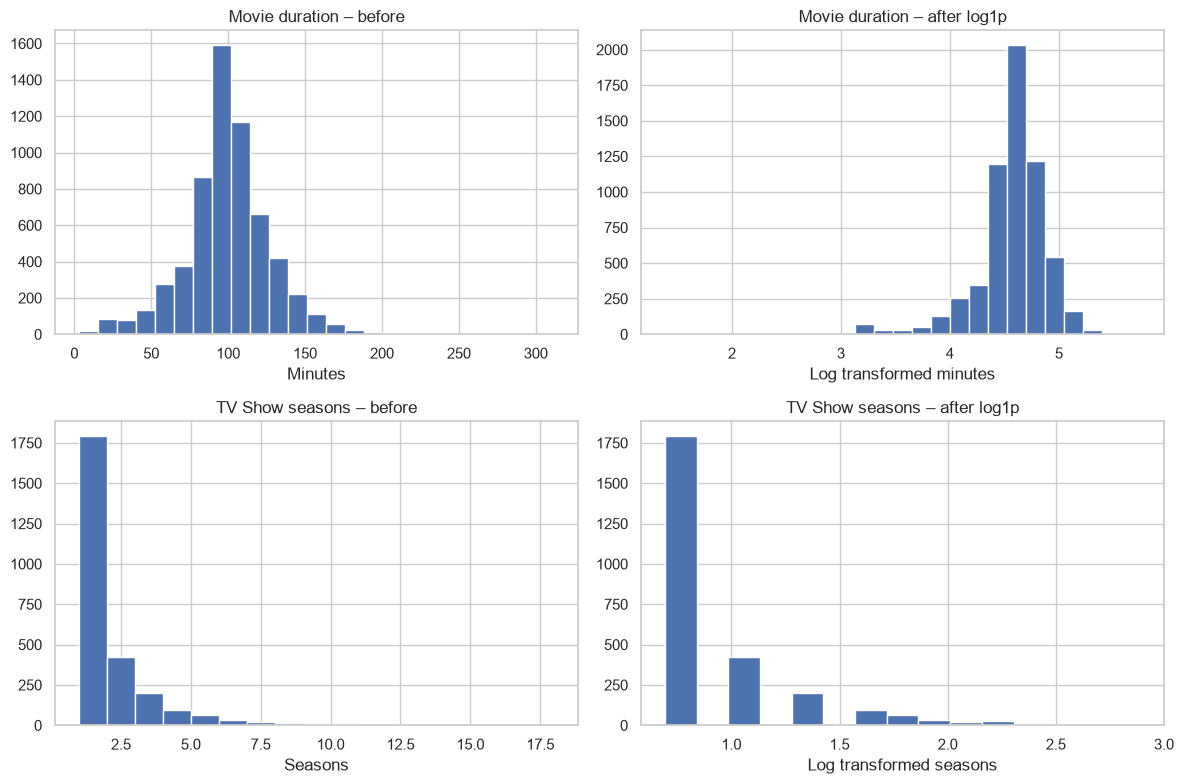

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(df["movie_duration_min"].dropna(), bins=25)
axes[0, 0].set_title("Movie duration – before")
axes[0, 0].set_xlabel("Minutes")

axes[0, 1].hist(df_week6["movie_duration_log1p"].dropna(), bins=25)
axes[0, 1].set_title("Movie duration – after log1p")
axes[0, 1].set_xlabel("Log transformed minutes")

axes[1, 0].hist(df["tv_seasons"].dropna(), bins=range(1, int(df["tv_seasons"].max()) + 2))
axes[1, 0].set_title("TV Show seasons – before")
axes[1, 0].set_xlabel("Seasons")

axes[1, 1].hist(df_week6["tv_seasons_log1p"].dropna(), bins=15)
axes[1, 1].set_title("TV Show seasons – after log1p")
axes[1, 1].set_xlabel("Log transformed seasons")

plt.tight_layout()
plt.show()


## 8. Saving the Feature-Engineered Files

I save the working DataFrame as `netflix_feature_engineered.csv`. It contains the extracted duration features, scaled columns and log-transformed columns along with the original cleaned information.

I save the one-hot encoded `type` and `rating` columns separately as `netflix_categorical_encoded.csv`. This keeps the expanded encoded table separate from the main feature-engineered dataset. Neither output overwrites the original cleaned CSV.

In [10]:
output_dir = Path("Dataset")
output_dir.mkdir(exist_ok=True)

df_week6.to_csv(output_dir / "netflix_feature_engineered.csv", index=False)
encoded_categories.to_csv(output_dir / "netflix_categorical_encoded.csv", index=False)

print("Saved:")
print(output_dir / "netflix_feature_engineered.csv")
print(output_dir / "netflix_categorical_encoded.csv")
print("Feature-engineered shape:", df_week6.shape)

Saved:
Dataset\netflix_feature_engineered.csv
Dataset\netflix_categorical_encoded.csv
Feature-engineered shape: (8807, 22)


## 9. Week 6 – Short Report

In Week 6, I prepared additional features from the cleaned Netflix catalogue. I separated the mixed `duration` field into movie runtime in minutes and TV Show season count because they use different units. I scaled the numerical features using both Min-Max scaling and standardization, and compared the results in a summary table.

For categorical data, I used **One-Hot Encoding** through `pandas.get_dummies()` on `type` and `rating`. This creates separate 0/1 columns for each category without giving the categories an artificial order. I checked skewness for movie runtime and TV Show season count, then compared their original distributions with their `log1p`-transformed distributions using histograms. The histograms were chosen because they make the shape and right tail of each distribution easy to inspect.

**Conclusion:** The feature-engineered dataset now contains separate duration measurements, scaled numerical features and log-transformed versions for further analysis. The categorical encoding is saved in a separate file. These features describe the Netflix catalogue, not individual viewing sessions, so they do not directly measure actual binge-watching or screen time.

In [11]:
print("WEEK 6 SUMMARY")
print("----------------")
print("Original records:", len(df))
print("Extracted numeric features: movie_duration_min, tv_seasons")
print("Scaled features:", ", ".join(numeric_features))
print("Categorical variables encoded: type, rating")
print("\nSkewness comparison:")
display(skew_comparison.round(3))
print("Feature-engineered dataset saved successfully.")

WEEK 6 SUMMARY
----------------
Original records: 8807
Extracted numeric features: movie_duration_min, tv_seasons
Scaled features: release_year, movie_duration_min, tv_seasons
Categorical variables encoded: type, rating

Skewness comparison:


,Skewness before,Skewness after log1p
movie_duration_min,0.203,-2.010
tv_seasons,3.419,1.805


Feature-engineered dataset saved successfully.
